# Exploratory Data Analysis

In [ ]:
import pandas as pd
pl = pd.read_csv("players_data-2025_2026.csv")
print(pl.shape)
print(pl.columns.tolist())
print(pl.head())


(2839, 102)
['Rk', 'Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'Born', 'MP', 'Starts', 'Min', '90s', 'Gls', 'Ast', 'G+A', 'G-PK', 'PK', 'PKatt', 'CrdY', 'CrdR', 'G+A-PK', 'Rk_stats_keeper', 'Nation_stats_keeper', 'Pos_stats_keeper', 'Comp_stats_keeper', 'Age_stats_keeper', 'Born_stats_keeper', 'MP_stats_keeper', 'Starts_stats_keeper', 'Min_stats_keeper', '90s_stats_keeper', 'GA', 'GA90', 'SoTA', 'Saves', 'Save%', 'W', 'D', 'L', 'CS', 'CS%', 'PKatt_stats_keeper', 'PKA', 'PKsv', 'PKm', 'Rk_stats_shooting', 'Nation_stats_shooting', 'Pos_stats_shooting', 'Comp_stats_shooting', 'Age_stats_shooting', 'Born_stats_shooting', '90s_stats_shooting', 'Gls_stats_shooting', 'Sh', 'SoT', 'SoT%', 'Sh/90', 'SoT/90', 'G/Sh', 'G/SoT', 'PK_stats_shooting', 'PKatt_stats_shooting', 'Rk_stats_playing_time', 'Nation_stats_playing_time', 'Pos_stats_playing_time', 'Comp_stats_playing_time', 'Age_stats_playing_time', 'Born_stats_playing_time', 'MP_stats_playing_time', 'Min_stats_playing_time', 'Mn/MP', 'M

We decide to keep only players with at least 900 minutes, remove goalkeepers, and create the primary and secondary positions

In [ ]:
pl = pl[~pl["Pos"].str.contains("GK", na=False)].copy()

pl["Primary_Pos"] = pl["Pos"].str.split(",").str[0]
pl["Secondary_Pos"] = pl["Pos"].str.split(",").str[1]

pl = pl[pl["Min"] >= 900].copy()

print(pl.head())

   Rk             Player  Nation    Pos         Squad                Comp  \
0   1   Brenden Aaronson  us USA  MF,FW  Leeds United  eng Premier League   
5   6      Himad Abdelli  dz ALG     MF        Angers          fr Ligue 1   
6   7           Ali Abdi  tn TUN  MF,DF          Nice          fr Ligue 1   
7   8  Salis Abdul Samed  gh GHA     MF          Nice          fr Ligue 1   
8   9    Saud Abdulhamid  sa KSA     MF          Lens          fr Ligue 1   

    Age    Born  MP  Starts  ...  2CrdY  Fls  Fld  Off  Crs  Int  TklW  OG  \
0  24.0  2000.0  37      30  ...      0   20   51    5   37   17    27   0   
5  25.0  1999.0  13      11  ...      0   16   12    1    9   13    17   0   
6  31.0  1993.0  22      13  ...      1   22   18    1   33   10    11   0   
7  25.0  2000.0  18      12  ...      0   19   10    0    2   11     7   0   
8  26.0  1999.0  25      14  ...      0   26   14    1   47    9    22   0   

   Primary_Pos  Secondary_Pos  
0           MF             FW  
5   

The dataset is for an entire football season, and one peculiarity is that a player can appear twice. The reason for this is because they might play the first half of the season (May to December), then transfer to a different team and play the second half of the season with a different team. As it is a possibility a player can have the same name, we make sure that their birth year matches, making it very unprobable for two players with the same name and the same birth year matching, we also mark these players with a boolean column titled "Transfered?" to ensure that we have a way to track and verify these players.Additionally, we don't match nationalities as their has been cases of players changing their nationallity for eligibility for World Cup tournaments.

In [ ]:
counts = pl["Player"].value_counts()

duplicates = counts[counts > 1]

print("Players with repeated names:", len(duplicates))
print("Total rows involving repeated names:", duplicates.sum())
print(duplicates)

Players with repeated names: 7
Total rows involving repeated names: 14
Player
Marc Guéhi              2
Nicolás González        2
Antoine Semenyo         2
Jørgen Strand Larsen    2
Vitinha                 2
Unai Núñez              2
Sebastiano Luperto      2
Name: count, dtype: int64


In [ ]:
pl["Transfered?"] = pl.duplicated(["Player", "Born"], keep=False)

stats = [
    "MP", "Starts", "Min", "90s",
    "Gls", "Ast", "xG", "xAG", "npxG", "G-PK",
    "Tkl", "TklW", "Blocks", "Int", "Clr",
    "PrgP", "PrgC", "KP", "xA", "PPA",
    "Touches", "Carries", "Mis", "Dis",
    "CrdY", "CrdR", "Recov"
]

stats = [col for col in stats if col in pl.columns]

totals = pl.groupby(["Player", "Born"])[stats].sum(min_count=1)

pl = pl.drop_duplicates(["Player", "Born"], keep="last")
pl = pl.drop(columns=stats)

pl = pl.merge(totals, on=["Player", "Born"], how="left")

print("Transferred players:", pl["Transfered?"].sum())
print("Total players:", len(pl))

Transferred players: 6
Total players: 1458


Now that the data is clean, we select the relevant stats we will be using for each position group, as well as converting everything per 90 minutes

In [ ]:
fw = ["G-PK", "Ast", "Sh", "SoT", "Off"]
mf = ["Ast", "Sh", "TklW", "Int", "Crs"]
df_stats = ["TklW", "Int", "Fls", "Crs", "Fld"]

stats = list(dict.fromkeys(fw + mf + df_stats))

pl = pl[pl["90s"] > 0].copy()

for col in stats:
    pl[col + "_p90"] = pl[col] / pl["90s"]

info = [
    "Player", "Born", "Nation", "Age",
    "Squad", "Comp", "Pos",
    "Primary_Pos", "Secondary_Pos",
    "Transfered?", "Min", "90s"
]

pl = pl[info + [col + "_p90" for col in stats]].copy()

pl.to_csv("players_cleaned.csv", index=False)

print(pl.shape)

(1458, 22)


We save this new data set as a CSV, and then we can begin the EDA

We first want to understand the distribution of a fundamental statistic for forwards, in this case we can see how the normal distribution assumption seems appropiate

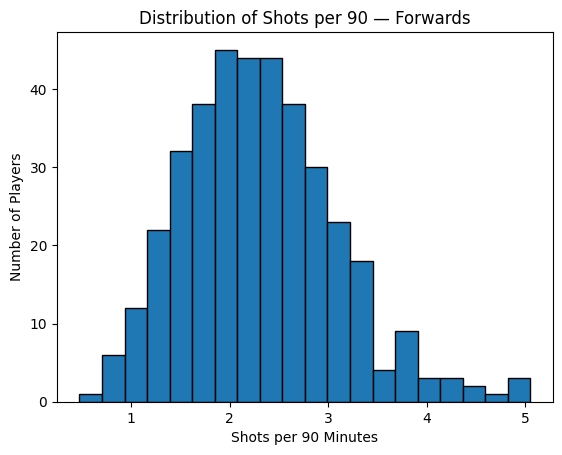

In [ ]:
import matplotlib.pyplot as plt

forwards = pl[
    (pl["Primary_Pos"] == "FW") |
    (pl["Secondary_Pos"] == "FW")
]

plt.hist(forwards["Sh_p90"].dropna(), bins=20, edgecolor="black")

plt.xlabel("Shots per 90 Minutes")
plt.ylabel("Number of Players")
plt.title("Distribution of Shots per 90 — Forwards")
plt.show()


We want to ensure that there is a positive correlation between shots and shots on target, as these variables are related but have a different impact on the game

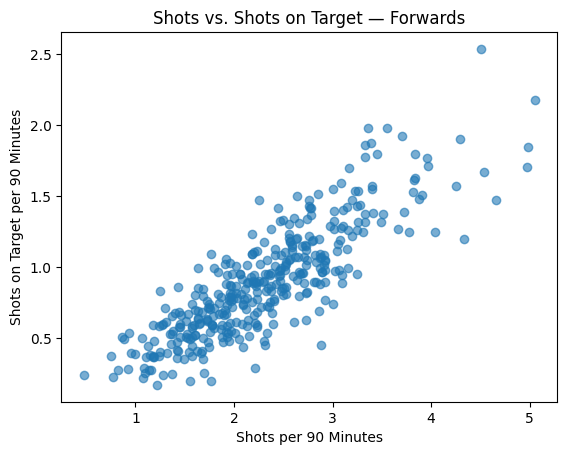

In [ ]:
plt.scatter(forwards["Sh_p90"], forwards["SoT_p90"], alpha=0.6)
plt.xlabel("Shots per 90 Minutes")
plt.ylabel("Shots on Target per 90 Minutes")
plt.title("Shots vs. Shots on Target — Forwards")
plt.show()

The purpose of the following graph is to illustrate why we should separate into groups with a universal statistic such as tackles won, in this case, we can see how despite there being a small difference between midfielders and defenders for this statistic, using it to evaluate forwards could be problematic if we ignore position as a key separating factor

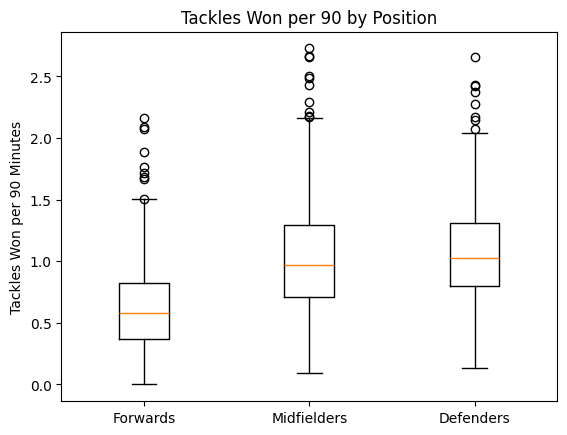

In [ ]:
fw_tkl = pl[
    (pl["Primary_Pos"] == "FW") |
    (pl["Secondary_Pos"] == "FW")
]["TklW_p90"].dropna()

mf_tkl = pl[
    (pl["Primary_Pos"] == "MF") |
    (pl["Secondary_Pos"] == "MF")
]["TklW_p90"].dropna()

df_tkl = pl[
    (pl["Primary_Pos"] == "DF") |
    (pl["Secondary_Pos"] == "DF")
]["TklW_p90"].dropna()

plt.boxplot(
    [fw_tkl, mf_tkl, df_tkl],
    tick_labels=["Forwards", "Midfielders", "Defenders"]
)

plt.ylabel("Tackles Won per 90 Minutes")
plt.title("Tackles Won per 90 by Position")
plt.show()

Finally, we want to ensure all players we are including in our data set have complete relevant statistics, and we want to understand the sample of each position group

In [ ]:
print("Dataset shape:", pl.shape)
print("Missing values:")
print(pl.isnull().sum())

for pos in ["FW", "MF", "DF"]:
    count = (
        (pl["Primary_Pos"] == pos)).sum()

    print(pos, count)

Dataset shape: (1458, 22)
Missing values:
Player              0
Born                0
Nation              0
Age                 0
Squad               0
Comp                0
Pos                 0
Primary_Pos         0
Secondary_Pos    1060
Transfered?         0
Min                 0
90s                 0
G-PK_p90            0
Ast_p90             0
Sh_p90              0
SoT_p90             0
Off_p90             0
TklW_p90            0
Int_p90             0
Crs_p90             0
Fls_p90             0
Fld_p90             0
dtype: int64
FW 229
MF 703
DF 526


Secondary position having a large amount of missing values is expected, as not every player has two positions attached to them, we finally report our sample size as the following:
378 Unique Forwards
876 Unique Midfielders
602 Unique Defenders

In [ ]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(0)

pA, pB, n = 0.10, 0.12, 1000
xA, xB = rng.binomial(n, pA), rng.binomial(n, pB)

a, b = 1, 1

postA = stats.beta(a + xA, b + n - xA)
postB = stats.beta(a + xB, b + n - xB)

w = n / (a + b + n)

print(postA.mean(), (1-w)*a/(a+b) + w*xA/n)

M = 100_000
I = postB.rvs(M, random_state=rng) > postA.rvs(M, random_state=rng)
p_hat = I.mean(); se = np.sqrt(p_hat*(1-p_hat)/M)
pool = (xA + xB) / (2*n)
z = (xB/n - xA/n) / np.sqrt(pool*(1-pool)*(2/n))
print(p_hat, se, z, 2*stats.norm.sf(abs(z)))

# Simulation

we choose a known population mean vector and covariance matrix for the simulation, the true values are expected to be recoverd

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2
rng = np.random.default_rng(2026)
n = 10000
d = 5
mu = np.array([2, 1, 3, 1, 0.5])
Sigma = np.array([
    [1, 0.4, 0, 0, 0],
    [0.4, 1, 0, 0, 0],
    [0, 0, 1, 0, 0],
    [0, 0, 0, 1, 0],
    [0, 0, 0, 0, 1]
])

We use an off-diagonal value of 0.4 to illustrate the first two simulated variables being positively correlated, as its the case that we hypothesize would happen in our data, and why covariance matters for anomaly detection

We now generate 10,000 independent observations from the known multivariate normal distribution

In [ ]:
X = rng.multivariate_normal(mu, Sigma, size=n)
print("Simulated dataset shape:", X.shape)
print("First five observations:")
print(X[:5])

Simulated dataset shape: (10000, 5)
First five observations:
[[2.31396544 2.0131823  1.10367365 2.39577171 0.74057128]
 [2.36807984 1.12060908 3.30383537 0.7323397  0.18805067]
 [1.30941054 0.48568554 2.93587206 0.91452344 1.01470521]
 [3.26652887 0.76092043 3.54826018 0.86951721 0.09624974]
 [2.04777163 1.75086843 2.76771723 0.85126719 1.15662161]]


As expected, our matrix has the shape (10000, 5), with each row representing an artificial five dimensional observation, similar to how each player will be eventually represented by five per 90 statistic

We now verify the Maximum Likelihood Estimators, as seen in Question 1 from our math section in Overleaf. We calculate the sample mean and covariance matrix

In [ ]:
mu_hat = np.mean(X, axis=0)
centered = X - mu_hat
Sigma_hat = np.dot(centered.T, centered) / n
print("True mean:", mu)
print("Estimated mean:", mu_hat)
print("True covariance:")
print(Sigma)
print("Estimated covariance:")
print(Sigma_hat)

True mean: [2.  1.  3.  1.  0.5]
Estimated mean: [1.9926656  0.98136563 2.99732056 0.9889917  0.50463828]
True covariance:
[[1.  0.4 0.  0.  0. ]
 [0.4 1.  0.  0.  0. ]
 [0.  0.  1.  0.  0. ]
 [0.  0.  0.  1.  0. ]
 [0.  0.  0.  0.  1. ]]
Estimated covariance:
[[ 0.99959902  0.4065394  -0.00129081 -0.00514645  0.0083112 ]
 [ 0.4065394   1.02221122 -0.00611898 -0.00776989 -0.00717485]
 [-0.00129081 -0.00611898  0.97619402 -0.00553385  0.00394719]
 [-0.00514645 -0.00776989 -0.00553385  1.0025191   0.00507472]
 [ 0.0083112  -0.00717485  0.00394719  0.00507472  0.98852475]]


The formulas derived in Q1 produce estimates close to the true mean and covariance when applied to the chosen 10,000 samples from the normal distribution

We now apply whitening, and we want to verify that it transforms our simulated data for every variable to have a variance of approximately 1, and every pair of different variables having a covariance approximately 0

In [ ]:
eigenvalues, Q = np.linalg.eigh(Sigma)
Lambda_inv_sqrt = np.diag(1 / np.sqrt(eigenvalues))
Sigma_inv_sqrt = np.dot(
    np.dot(Q, Lambda_inv_sqrt), Q.T
)
Z = np.dot(X - mu, Sigma_inv_sqrt)
Z_cov = np.cov(Z, rowvar=False, bias=True)
print("Whitened covariance:")
print(Z_cov)
print("Expected covariance:")
print(np.eye(d))


Whitened covariance:
[[ 9.97532315e-01  2.59208646e-03 -1.46326622e-05 -3.76472156e-03
   1.04764028e-02]
 [ 2.59208646e-03  1.02220425e+00 -6.24778164e-03 -7.15157701e-03
  -9.51600626e-03]
 [-1.46326622e-05 -6.24778164e-03  9.76194024e-01 -5.53385412e-03
   3.94719242e-03]
 [-3.76472156e-03 -7.15157701e-03 -5.53385412e-03  1.00251910e+00
   5.07472130e-03]
 [ 1.04764028e-02 -9.51600626e-03  3.94719242e-03  5.07472130e-03
   9.88524752e-01]]
Expected covariance:
[[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]]


As we can see, the simulated variance stands very close to the expected variance, and we can see how whitening reduced the covariance to around 0.0026. This is important as like we mentioned, some of the variables chosen as features in our dataset might present covariance, specifically the shots and shots on target. Our simulation is consistent with the results of Question 4 of the math quesitions.

We now want to evaluate the results from Question 2 and Question 3, and to do so, we first calculate the Mahalanobis distance, and subtract the true population mean from each observation

In [ ]:
Sigma_inv = np.linalg.inv(Sigma)
centered = X - mu
D2 = np.sum(
    np.dot(centered, Sigma_inv) * centered,
    axis=1
)
print("Minimum squared distance:", np.min(D2))
print("Simulated mean:", np.mean(D2))
print("Theoretical mean:", d)
print("Simulated variance:", np.var(D2))
print("Theoretical variance:", 2 * d)


Minimum squared distance: 0.016210539916987475
Simulated mean: 4.987471567611849
Theoretical mean: 5
Simulated variance: 9.8804376345506
Theoretical variance: 10


The smallest distance is non-negative, which satisfies the property of no Mahalanobis distance being negative. Additionally, the average squared distance and the spread of our simulated distances are very close to what the chi-square model predicted

We now want to verify the Chi-Squared False-Alarm rate described in Question 5. We want to test to see if our theoretical anomaly threshold produces approximately 5% of false alarms

In [ ]:
alpha = 0.05
threshold = chi2.ppf(1 - alpha, d)
anomalies = D2 > threshold
observed_rate = np.mean(anomalies)
print("Theoretical threshold:", threshold)
print("Expected false-alarm rate:", alpha)
print("Observed false-alarm rate:", observed_rate)
print("Number of flagged observations:", np.sum(anomalies))

Theoretical threshold: 11.070497693516351
Expected false-alarm rate: 0.05
Observed false-alarm rate: 0.0484
Number of flagged observations: 484


Once again, we can see how our observed false-alarm rate and our expected false-alarm rate are fairly similar to each other, were any observation with a squared Mahalanobis distance greater than 11.07 would be clasified as anomalous. These results are all consistent with the theoretical false-alarm rate of 0.05

We now generate a table with all the results from our simulation

In [ ]:
results = pd.DataFrame({
    "Quantity": [
        "Mean of Variable 1",
        "Mean of Variable 2",
        "Variance of Variable 1",
        "Covariance of Variables 1 and 2",
        "Whitened Variance of Variable 1",
        "Whitened Covariance of Variables 1 and 2",
        "Mean Squared Mahalanobis Distance",
        "Variance of Squared Mahalanobis Distance",
        "False-Alarm Rate"
    ],
    "Theoretical": [
        mu[0],
        mu[1],
        Sigma[0, 0],
        Sigma[0, 1],
        1,
        0,
        d,
        2 * d,
        alpha
    ],
    "Simulated": [
        mu_hat[0],
        mu_hat[1],
        Sigma_hat[0, 0],
        Sigma_hat[0, 1],
        Z_cov[0, 0],
        Z_cov[0, 1],
        np.mean(D2),
        np.var(D2),
        observed_rate
    ]
})

print(results.round(4).to_string(index=False))

                                Quantity  Theoretical  Simulated
                      Mean of Variable 1         2.00     1.9927
                      Mean of Variable 2         1.00     0.9814
                  Variance of Variable 1         1.00     0.9996
         Covariance of Variables 1 and 2         0.40     0.4065
         Whitened Variance of Variable 1         1.00     0.9975
Whitened Covariance of Variables 1 and 2         0.00     0.0026
       Mean Squared Mahalanobis Distance         5.00     4.9875
Variance of Squared Mahalanobis Distance        10.00     9.8804
                        False-Alarm Rate         0.05     0.0484
